# Supernova cosmology: a summer-school reconstruction
**Project by Ansh Shinde.** Reconstructed from the supplied PDF export of `2_hubble_parameter.ipynb`, with corrections and rerun outputs, on 4 November 2026. This is not the recovered original notebook. The original exercise included instructor-provided explanations and code scaffolding; their authorship is not claimed here. Reconstruction and review were assisted by ChatGPT.

We use Type Ia supernova distance moduli to practise numerical integration, weighted fitting, residual analysis, and age estimation in flat $\Lambda$CDM.

> **Scope:** This notebook reproduces an educational approximation. It uses the released diagonal distance-modulus errors to reproduce the original exercise, although the dataset authors explicitly require the full covariance for cosmological inference. Its parameter errors are conditional, diagonal-only fit errors, not complete cosmological uncertainties. It must not be used to claim a new measurement of the Hubble tension or evidence for evolving dark energy.

`MU_SH0ES` already includes a SH0ES absolute-magnitude calibration. The inferred distance scale is conditional on that calibration. A proper distance-ladder analysis requires the official calibrated likelihood, covariance, calibrator treatment, and sample selections.

**Run:** install the packages in `requirements.txt`, then run all cells in order. The notebook also works in Colab after installing those packages. The first run downloads the official data (about 0.6 MB); subsequent runs use the local cache. Figures are written to `figures/` and numeric results to `results.json`.

In [1]:
from pathlib import Path
import hashlib
import json
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import curve_fit
from astropy.constants import c
from astropy import units as u
from astropy.cosmology import FlatLambdaCDM

plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
Path('figures').mkdir(exist_ok=True)
C_KMS = c.to_value(u.km/u.s)

## 1. Load and validate the official data
The SHA-256 checksum records the exact file used for this reconstruction. If the upstream file changes, download the reviewed version or review that change before updating the checksum. The full table contains 1701 light-curve entries; entries must not be assumed to represent independent supernovae.

The original exercise uses all finite rows with positive redshift and uncertainty. This preserves its selection for reproducibility; it does not reproduce the official cosmology sample selection. Very low-redshift objects require particular care because peculiar velocities are important.

In [2]:
DATA_URL = ('https://raw.githubusercontent.com/PantheonPlusSH0ES/DataRelease/main/'
            'Pantheon%2B_Data/4_DISTANCES_AND_COVAR/Pantheon%2BSH0ES.dat')
EXPECTED_SHA256 = '1cb0fc379ef066afdc2ffd1857681cc478024570d8a3eba284fb645775198cf8'
data_path = Path('data/Pantheon+SH0ES.dat')
data_path.parent.mkdir(exist_ok=True)
if not data_path.exists():
    with urlopen(DATA_URL, timeout=60) as response:
        raw = response.read()
    if hashlib.sha256(raw).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Upstream data changed: review before updating the checksum.')
    data_path.write_bytes(raw)
if hashlib.sha256(data_path.read_bytes()).hexdigest() != EXPECTED_SHA256:
    raise ValueError('Cached data do not match the reviewed file.')

table = pd.read_csv(data_path, sep=r'\s+', comment='#')
columns = ['zHD', 'MU_SH0ES', 'MU_SH0ES_ERR_DIAG']
values = table[columns].to_numpy(dtype=float)
valid = np.isfinite(values).all(axis=1) & (values[:, 0] > 0) & (values[:, 2] > 0)
z, mu_obs, mu_err = values[valid].T
print(f'Used {len(z)} of {len(table)} light-curve entries.')
print(f'Redshift range: {z.min():.5f} to {z.max():.5f}')

Used 1701 of 1701 light-curve entries.
Redshift range: 0.00122 to 2.26137


## 2. Flat $\Lambda$CDM model
Assume zero curvature, $w=-1$, and negligible radiation:
$$E(z)=\sqrt{\Omega_m(1+z)^3+1-\Omega_m},\qquad H(z)=H_0E(z).$$
$$d_L(z)=(1+z)\frac{c}{H_0}\int_0^z\frac{dz'}{E(z')},\qquad
\mu(z)=5\log_{10}\!\left(\frac{d_L}{\mathrm{Mpc}}\right)+25.$$
Here $H_0$ is in km s$^{-1}$ Mpc$^{-1}$ and $c$ is in km s$^{-1}$.

To reproduce the PDF, this single-redshift approximation uses `zHD` in both factors. A precise implementation must distinguish the observed heliocentric redshift in the distance prefactor from the corrected Hubble-diagram redshift used for the cosmological distance, following the official likelihood.

In [3]:
def E(z, Omega_m):
    return np.sqrt(Omega_m*(1 + np.asarray(z))**3 + 1 - Omega_m)

def luminosity_distance(z, H0, Omega_m):
    integral, _ = quad(lambda zp: 1/E(zp, Omega_m), 0, float(z))
    return (1 + z)*C_KMS/H0*integral

def mu_theory(z, H0, Omega_m):
    distances = np.array([luminosity_distance(zi, H0, Omega_m)
                          for zi in np.atleast_1d(z)])
    return 5*np.log10(distances) + 25

popt, pcov = curve_fit(
    mu_theory, z, mu_obs, p0=[70, 0.3], sigma=mu_err,
    absolute_sigma=True, bounds=([1, 0.001], [200, 0.999])
)
H0_fit, Omega_m_fit = popt
H0_err, Omega_m_err = np.sqrt(np.diag(pcov))
print(f'H0 = {H0_fit:.3f} +/- {H0_err:.3f} km/s/Mpc')
print(f'Omega_m = {Omega_m_fit:.4f} +/- {Omega_m_err:.4f}')
print('Errors above are conditional diagonal-only fit errors.')

H0 = 72.974 +/- 0.262 km/s/Mpc
Omega_m = 0.3508 +/- 0.0187
Errors above are conditional diagonal-only fit errors.


## 3. Hubble diagram and residuals
The first panel now includes the fitted model curve, missing from the original handout. Residuals include measurement error bars and weighted bin means. Bin errors assume independent entries and do not include model-parameter uncertainty; they are diagnostic only.

The diagonal reduced chi-square is not a full-covariance goodness-of-fit statistic. A value below one should not be described as proof of an excellent cosmological model.

Diagonal chi-square / degrees of freedom = 745.40 / 1699
Diagonal reduced chi-square = 0.439


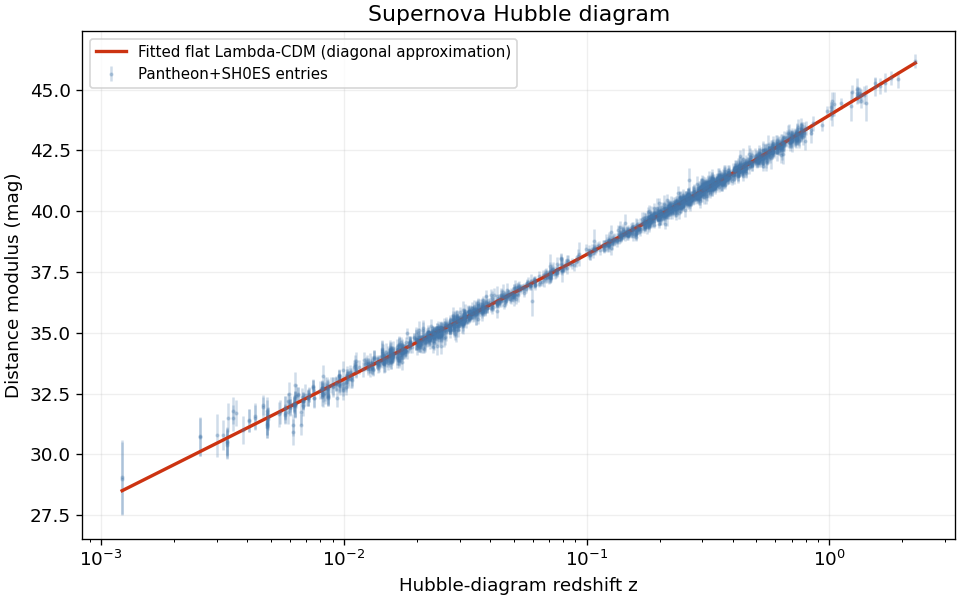

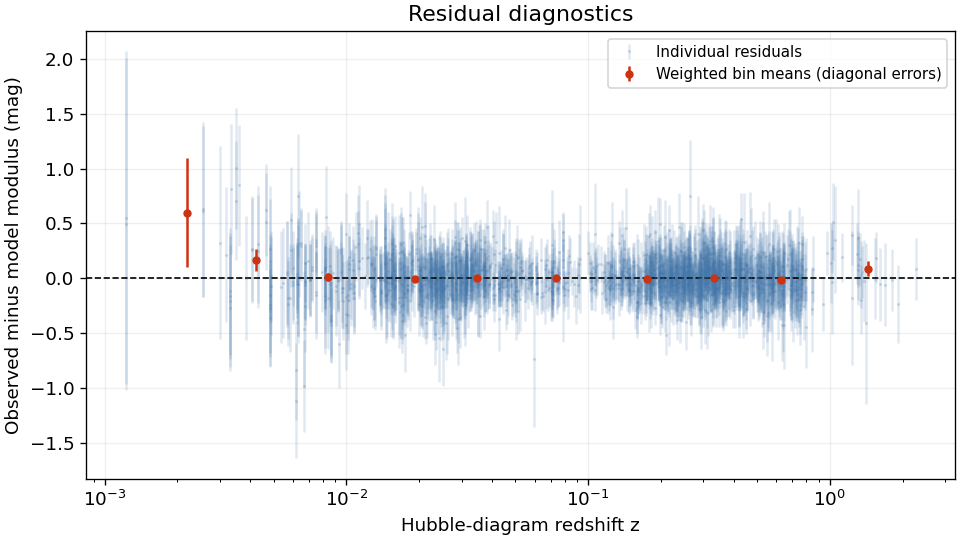

In [4]:
mu_model = mu_theory(z, *popt)
residuals = mu_obs - mu_model
chi2_diag = np.sum((residuals/mu_err)**2)
dof = len(z) - len(popt)
print(f'Diagonal chi-square / degrees of freedom = {chi2_diag:.2f} / {dof}')
print(f'Diagonal reduced chi-square = {chi2_diag/dof:.3f}')

z_grid = np.geomspace(z.min(), z.max(), 350)
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.errorbar(z, mu_obs, yerr=mu_err, fmt='.', ms=3, alpha=0.25,
            color='#4477AA', label='Pantheon+SH0ES entries')
ax.plot(z_grid, mu_theory(z_grid, *popt), color='#CC3311', lw=2,
        label='Fitted flat Lambda-CDM (diagonal approximation)')
ax.set(xscale='log', xlabel='Hubble-diagram redshift z',
       ylabel='Distance modulus (mag)', title='Supernova Hubble diagram')
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
fig.savefig('figures/hubble_diagram.png')
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.errorbar(z, residuals, yerr=mu_err, fmt='.', ms=2, alpha=0.16,
            color='#4477AA', label='Individual residuals')
edges = np.geomspace(z.min()*0.99, z.max()*1.01, 11)
for i, (left, right) in enumerate(zip(edges[:-1], edges[1:])):
    mask = (z >= left) & (z < right)
    if mask.sum() == 0:
        continue
    weights = 1/mu_err[mask]**2
    ax.errorbar(np.exp(np.average(np.log(z[mask]), weights=weights)),
                np.average(residuals[mask], weights=weights),
                yerr=1/np.sqrt(weights.sum()), fmt='o', color='#CC3311', ms=4,
                label='Weighted bin means (diagonal errors)' if i == 0 else None)
ax.axhline(0, color='black', ls='--', lw=1)
ax.set(xscale='log', xlabel='Hubble-diagram redshift z',
       ylabel='Observed minus model modulus (mag)', title='Residual diagnostics')
ax.legend(fontsize=9)
ax.grid(alpha=0.2)
fig.savefig('figures/residuals.png')
plt.show()

## 4. Age of the Universe
$$t_0=\frac{1}{H_0}\int_0^\infty\frac{dz}{(1+z)E(z)}.$$
This is a derived prediction of the assumed model. It is not an independent age measurement. The same matter-plus-$\Lambda$ approximation is used to arbitrarily high redshift, omitting the radiation era.

For the handout sensitivity calculation we hold $H_0=72.97$ fixed and vary only $\Omega_m$. The handout's requested $\Omega_m=0.3$ gives approximately 12.92 Gyr, while the jointly fitted parameters give approximately 12.36 Gyr.

In [5]:
def age_of_universe(H0, Omega_m):
    integral, _ = quad(lambda zp: 1/((1+zp)*E(zp, Omega_m)), 0, np.inf)
    hubble_time = (1/(H0*u.km/u.s/u.Mpc)).to_value(u.Gyr)
    return hubble_time*integral

age_fit = age_of_universe(H0_fit, Omega_m_fit)
print(f'Age at fitted parameters: {age_fit:.3f} Gyr')
age_rows = []
for om in [0.2, 0.3, 0.351, 0.4]:
    age = age_of_universe(72.97, om)
    age_rows.append({'H0': 72.97, 'Omega_m': om, 'age_Gyr': age})
    print(f'H0 = 72.97, Omega_m = {om:.3f}: {age:.3f} Gyr')

Age at fitted parameters: 12.358 Gyr
H0 = 72.97, Omega_m = 0.200: 14.419 Gyr
H0 = 72.97, Omega_m = 0.300: 12.919 Gyr
H0 = 72.97, Omega_m = 0.351: 12.357 Gyr
H0 = 72.97, Omega_m = 0.400: 11.899 Gyr


## 5. Corrected fixed-density fits
With $\Omega_m=0.3$ fixed, the fitting function must accept **only $H_0$** as an adjustable parameter. In the original PDF an extra unused parameter made the covariance singular and produced infinite uncertainties.

All errors below still use the diagonal approximation. The low/high-redshift difference is not evidence that $H_0$ evolves: $H_0$ is the present-day model parameter, and the expansion rate at redshift $z$ is $H(z)$. Differences between subset fits can reflect the fixed model, sample selection, correlated errors, and other systematics.

In [6]:
def mu_fixed_Om(z, H0):
    return mu_theory(z, H0, Omega_m=0.3)

fixed_results = {}
for label, mask in [('all', np.ones(len(z), dtype=bool)),
                    ('low_z', z < 0.1), ('high_z', z >= 0.1)]:
    fitted, covariance = curve_fit(
        mu_fixed_Om, z[mask], mu_obs[mask], p0=[70],
        sigma=mu_err[mask], absolute_sigma=True, bounds=([1], [200])
    )
    h0 = float(fitted[0])
    error = float(np.sqrt(covariance[0, 0]))
    fixed_results[label] = {'N': int(mask.sum()), 'H0': h0,
                            'H0_error_diagonal': error}
    print(f'{label:7s}: N={mask.sum():4d}, H0={h0:.3f} +/- {error:.3f} km/s/Mpc')
print('All fits in this section fix Omega_m = 0.3.')

all    : N=1701, H0=73.530 +/- 0.172 km/s/Mpc
low_z  : N= 741, H0=73.007 +/- 0.277 km/s/Mpc
high_z : N= 960, H0=73.848 +/- 0.218 km/s/Mpc
All fits in this section fix Omega_m = 0.3.


## 6. Numerical cross-checks
Compare distance moduli against Astropy with radiation switched off; compare the age integral against the analytic matter-plus-Lambda formula; and check the one-parameter fit against an exact weighted-intercept solution. These checks validate implementation of the chosen approximation, not its adequacy for precision cosmology.

In [7]:
test_z = np.array([0.002, 0.03, 0.1, 0.5, 1.0, 2.2])
reference = FlatLambdaCDM(H0=H0_fit, Om0=Omega_m_fit, Tcmb0=0)
np.testing.assert_allclose(mu_theory(test_z, *popt),
                           reference.distmod(test_z).value, atol=1e-7, rtol=0)
for om in [0.2, 0.3, 0.351, 0.4]:
    factor = 2/(3*np.sqrt(1-om))*np.arcsinh(np.sqrt((1-om)/om))
    analytic_age = factor*(1/(72.97*u.km/u.s/u.Mpc)).to_value(u.Gyr)
    np.testing.assert_allclose(age_of_universe(72.97, om), analytic_age, rtol=1e-9)
for label, mask in [('all', np.ones(len(z), dtype=bool)),
                    ('low_z', z < 0.1), ('high_z', z >= 0.1)]:
    weights = 1/mu_err[mask]**2
    offset = np.average(mu_obs[mask] - mu_fixed_Om(z[mask], 70), weights=weights)
    exact_h0 = 70*10**(-offset/5)
    exact_error = exact_h0*np.log(10)/5/np.sqrt(weights.sum())
    np.testing.assert_allclose(fixed_results[label]['H0'], exact_h0, rtol=1e-6)
    np.testing.assert_allclose(fixed_results[label]['H0_error_diagonal'],
                               exact_error, rtol=1e-5)
assert np.all(np.isfinite(pcov))
print('Passed: Astropy distances, analytic ages, and exact fixed-density fits.')

results = {
    'method': 'Educational diagonal-only, single-redshift approximation',
    'data_sha256': EXPECTED_SHA256, 'N': int(len(z)),
    'joint_fit': {'H0': float(H0_fit), 'H0_error_diagonal': float(H0_err),
                  'Omega_m': float(Omega_m_fit),
                  'Omega_m_error_diagonal': float(Omega_m_err),
                  'age_Gyr': float(age_fit)},
    'fixed_Omega_m_0.3': fixed_results, 'ages_at_H0_72.97': age_rows,
    'chi2_diagonal': float(chi2_diag), 'dof': int(dof),
}
Path('results.json').write_text(json.dumps(results, indent=2) + '\n')

Passed: Astropy distances, analytic ages, and exact fixed-density fits.


## 7. Interpretation and limits
- The reconstructed exercise recovers $H_0\simeq72.97$ and $\Omega_m\simeq0.351$. It demonstrates numerical fitting conditional on SH0ES calibration; it is not an independent distance-ladder result.
- Planck 2018 reports $H_0=67.4\pm0.5$ km s$^{-1}$ Mpc$^{-1}$ under base $\Lambda$CDM. This provides context, but the incomplete uncertainty model here does not justify calculating a new Hubble-tension significance.
- The diagonal reduced chi-square is about 0.439. Correlations are omitted and the supplied diagonal uncertainties are intended for plotting. This statistic alone cannot establish model adequacy.
- A Hubble diagram's apparent flattening depends on plotting transformations. It is not by itself a detection of acceleration. The assumed flat $\Lambda$CDM model predicts a transition from matter-era deceleration to late acceleration for these fitted parameters; an observational claim requires an appropriate model comparison and likelihood.
- The residual plot is a visual diagnostic, not a formal test proving absence of systematics.
- A precision extension should implement the official likelihood, use the full covariance, handle calibrators appropriately, distinguish redshift frames, justify redshift cuts, and propagate calibration and model uncertainty. Merely replacing a diagonal vector with a matrix does not complete that work.

## References and provenance
1. [Pantheon+SH0ES data release and column definitions](https://github.com/PantheonPlusSH0ES/DataRelease/tree/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR).
2. Brout et al. (2022), *The Pantheon+ Analysis: Cosmological Constraints*, ApJ 938, 110, [arXiv:2202.04077](https://arxiv.org/abs/2202.04077).
3. Riess et al. (2022), *A Comprehensive Measurement of the Local Value of the Hubble Constant with 1 km/s/Mpc Uncertainty from the Hubble Space Telescope and the SH0ES Team*, ApJL 934, L7, [arXiv:2112.04510](https://arxiv.org/abs/2112.04510).
4. Planck Collaboration (2020), *Planck 2018 results. VI. Cosmological parameters*, A&A 641, A6, [arXiv:1807.06209](https://arxiv.org/abs/1807.06209).

Source materials supplied by the project author: `vertopal.com_2_hubble_parameter(1).pdf`, `2_Supernova_Cosmology_Handout.pdf`, and `Supernova_Cosmology_DetailedSummary.pdf`. Their original text and figures are not redistributed in this package. The missing notebook's code was reconstructed from the PDF and corrected; the explanatory text here was rewritten. Original instructor attribution should be added when known. No license is asserted over third-party teaching material or data.